# 과제 2 — ACT 정책 학습 및 실로봇 평가

**과제 내용**: 과제 1에서 수집한 데이터셋으로 ACT 정책을 학습하고, 실제 로봇에서 10회 평가해 성공률을 측정한 뒤, 학습된 정책을 Huggingface Hub에 업로드한다.

### 실습 환경 — **LeRobot 0.6.0**
- Python 3.12 이상, PyTorch 2.7 이상이 필요하다.
- 실습 PC에는 `lerobot[all]==0.6.0`이 설치되어 있다. 개인 PC에서 하려면 같은 버전으로 설치한다.
  ```bash
  pip install "lerobot[all]==0.6.0"
  ```
  `all`에는 학습(wandb), 녹화·텔레오퍼레이션, SO-101 모터(feetech), Diffusion Policy, SmolVLA에 필요한 패키지가 모두 들어 있다. (0.6.0부터 extra 없이 `pip install lerobot`만 하면 학습·데이터셋 의존성이 빠지므로 주의)
- 0.6.0부터 **정책을 실로봇에서 돌리는 기능이 `lerobot-record`에서 `lerobot-rollout`으로 옮겨졌다.** 평가는 반드시 `lerobot-rollout`으로 한다(2-1 참고).

### 작성 요령
- 이 노트북을 본인 GitHub 저장소(과제 1과 같은 저장소, assignments 폴더)에 `assignment_2.ipynb`로 올린다.
- 학습과 평가는 **터미널에서** 진행하고 이 노트북에는 결과 확인 코드와 분석을 작성한다. (보고서를 노트북으로 작성하는 것이다.)
- 모든 코드 셀은 **실행한 뒤 출력 결과가 보이는 상태로** 커밋한다. (출력이 없으면 미제출로 간주)
- `[작성]` 표시가 있는 부분을 모두 채운다.

### 주의 사항
- 학습 데이터셋, 평가 데이터셋, 모델 repo는 모두 **public**으로 설정한다.
- 모델 가중치는 **Huggingface Hub에만** 올리고 GitHub에는 올리지 않는다. `.gitignore`에 `outputs/`를 추가할 것.
- **마감 시각 이후의 커밋은 반영하지 않는다.**

## 0. 제출 정보

In [1]:
# 본인 정보 및 과제 저장소 설정
STUDENT_ID = "2021136087"
NAME = "윤희건"
HF_USER = "yhks"

TASK = "Grab the black cube"

TRAIN_DATASET = f"{HF_USER}/my_task"
POLICY_REPO   = f"{HF_USER}/act_my_task"
# 2026-10-28에 lerobot-rollout episodic 전략으로 수집한 10회 평가 데이터셋
EVAL_DATASET  = "yhks/rollout_act_my_task_20261028_142910"
WANDB_URL     = "https://wandb.ai/yhkees-korea-university-of-technology-and-education/lerobot/runs/mdlile99"

print("학번/이름     :", STUDENT_ID, NAME)
print("태스크        :", TASK)
print("학습 데이터셋 :", f"https://huggingface.co/datasets/{TRAIN_DATASET}")
print("정책 모델     :", f"https://huggingface.co/{POLICY_REPO}")
print("평가 데이터셋 :", f"https://huggingface.co/datasets/{EVAL_DATASET}" if EVAL_DATASET else "(10회 평가 후 입력)")
print("wandb         :", WANDB_URL or "(다음 단계에서 확인)")


학번/이름     : 2021136087 윤희건
태스크        : Grab the black cube
학습 데이터셋 : https://huggingface.co/datasets/yhks/my_task
정책 모델     : https://huggingface.co/yhks/act_my_task
평가 데이터셋 : https://huggingface.co/datasets/yhks/rollout_act_my_task_20261028_142910
wandb         : https://wandb.ai/yhkees-korea-university-of-technology-and-education/lerobot/runs/mdlile99


In [2]:
# LeRobot 버전 확인 — 학습·평가에 사용한 환경과 같은 커널에서 실행할 것
from importlib.metadata import version, PackageNotFoundError
try:
    LEROBOT_VERSION = version("lerobot")
except PackageNotFoundError:
    LEROBOT_VERSION = None
print("lerobot 버전:", LEROBOT_VERSION or "(이 커널에 설치되어 있지 않음)")
print("버전 확인   :", "통과" if LEROBOT_VERSION and LEROBOT_VERSION.startswith("0.6.") else "0.6.x가 아님 — 실습 환경을 확인할 것")

lerobot 버전: 0.6.0
버전 확인   : 통과


→ 과제 1의 데이터셋을 반드시 사용하지 않아도 됨.

In [3]:
# Hub 접근 확인 — 세 repo 모두 "OK"가 나와야 한다
import json
from huggingface_hub import HfApi, hf_hub_download

api = HfApi()
checks = [(TRAIN_DATASET, "dataset"), (POLICY_REPO, "model"), (EVAL_DATASET, "dataset")]
for rid, rtype in checks:
    try:
        files = api.list_repo_files(rid, repo_type=rtype)
        print(f"OK   [{rtype:7}] {rid}  (파일 {len(files)}개)")
    except Exception as e:
        print(f"FAIL [{rtype:7}] {rid}  -> {type(e).__name__}: public 여부와 repo_id를 확인할 것")

OK   [dataset] yhks/my_task  (파일 11개)
OK   [model  ] yhks/act_my_task  (파일 9개)
OK   [dataset] yhks/rollout_act_my_task_20261028_142910  (파일 9개)


## 1. 학습 설정

### 1-1. 실행한 학습 명령어

처음에는 batch size 8로 학습했으며, 20,000 step 체크포인트 이후 batch size를 16으로 높이고 AMP를 활성화해 재개했다.

```bash
lerobot-train \
  --dataset.repo_id=yhks/my_task \
  --policy.type=act \
  --policy.device=cuda \
  --policy.repo_id=yhks/act_my_task \
  --output_dir=outputs/train/act_my_task \
  --job_name=act_my_task \
  --batch_size=8 \
  --steps=100000 \
  --wandb.enable=true
```

```bash
lerobot-train \
  --config_path=outputs/train/act_my_task/checkpoints/last/pretrained_model/train_config.json \
  --resume=true \
  --batch_size=16 \
  --policy.use_amp=true
```

### 1-2. 학습 환경

- GPU: NVIDIA GeForce RTX 5070 Laptop GPU (1개)
- 학습 step 수: 100,000
- 소요 시간: 약 10시간 35분 (WandB 누적 실행 시간 기준)
- 기본값에서 변경한 하이퍼파라미터와 이유: 초기에는 기본 batch size 8을 사용했다. 20,000 step 이후에는 GPU 메모리를 더 활용하고 처리량을 높이기 위해 batch size를 16으로 변경하고 AMP를 활성화하여 학습을 재개했다.


In [4]:
# 업로드된 정책의 설정 확인
import os
import tempfile

def load_json(repo_id, filename, repo_type="model"):
    try:
        cache_dir = os.path.join(tempfile.gettempdir(), "lerobot_assignment_2_hf_cache")
        path = hf_hub_download(repo_id, filename, repo_type=repo_type, cache_dir=cache_dir)
        with open(path, encoding="utf-8") as file:
            return json.load(file)
    except Exception as e:
        print(f"{filename} 불러오기 실패: {type(e).__name__}")
        return None

policy_cfg = load_json(POLICY_REPO, "config.json")
if policy_cfg:
    print("== 정책 설정 (config.json) ==")
    for k in ["type", "chunk_size", "n_action_steps", "n_obs_steps",
              "vision_backbone", "dim_model", "use_vae", "kl_weight", "optimizer_lr"]:
        if k in policy_cfg:
            print(f"{k:16}: {policy_cfg[k]}")

train_cfg = load_json(POLICY_REPO, "train_config.json")
if train_cfg:
    print("\n== 학습 설정 (train_config.json) ==")
    print("dataset   :", train_cfg.get("dataset", {}).get("repo_id"))
    for k in ["steps", "batch_size", "seed"]:
        if k in train_cfg:
            print(f"{k:10}: {train_cfg[k]}")

== 정책 설정 (config.json) ==
type            : act
chunk_size      : 100
n_action_steps  : 100
n_obs_steps     : 1
vision_backbone : resnet18
dim_model       : 512
use_vae         : True
kl_weight       : 10.0
optimizer_lr    : 1e-05

== 학습 설정 (train_config.json) ==
dataset   : yhks/my_task
steps     : 100000
batch_size: 16
seed      : 1000


### 1-3. 학습 곡선

WandB 실행 기록과 로컬 학습 로그를 확인했다. 학습 loss는 초기에 빠르게 감소한 뒤 완만하게 수렴했으며, 마지막 100,000 step 부근에서는 약 0.065 수준이었다.

![ACT training loss](images/loss_curve.png)


In [5]:
# (선택) wandb에서 loss를 CSV로 내보낸 경우 직접 그리기
# CSV에 step 열과 loss 열이 있다고 가정 — 열 이름은 본인 파일에 맞게 수정
import os
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "images/loss.csv"
if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
    plt.figure(figsize=(7, 4))
    plt.plot(df.iloc[:, 0], df.iloc[:, 1])
    plt.xlabel("step"); plt.ylabel("loss"); plt.title("Training loss")
    plt.grid(alpha=0.3); plt.show()
else:
    print("CSV 없음 — 위 마크다운의 이미지로 대체")

CSV 없음 — 위 마크다운의 이미지로 대체


## 2. 실로봇 평가 (10회)

### 2-1. 평가 명령어

LeRobot 0.6.0의 `episodic` 전략으로 10개 평가 에피소드를 녹화한다. 리더 암은 현재 연결되어 있지 않으므로 사용하지 않으며, 각 회차 사이에 follower가 시작 자세로 자동 복귀한다. reset 시간 동안 큐브를 원래 위치에 다시 놓는다.

```bash
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path="yhks/act_my_task" \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM0 \
  --robot.id=follower1 \
  --robot.max_relative_target=5 \
  --robot.cameras="{ overhead: {type: opencv, index_or_path: /dev/video6, width: 640, height: 480, fps: 25}, wrist: {type: opencv, index_or_path: /dev/video4, width: 640, height: 480, fps: 25}}" \
  --dataset.repo_id="yhks/rollout_act_my_task" \
  --dataset.single_task="Grab the black cube" \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=30 \
  --dataset.reset_time_s=15 \
  --dataset.streaming_encoding=false \
  --dataset.num_image_writer_threads_per_camera=2 \
  --dataset.push_to_hub=true
```

키보드 조작은 `→` 현재 회차 조기 종료, `←` 현재 회차 폐기 후 재녹화, `ESC` 전체 세션 종료이다.


In [6]:
# 평가 데이터셋 메타데이터 확인 — 에피소드 수가 10이어야 한다
info = load_json(EVAL_DATASET, "meta/info.json", repo_type="dataset")
if info:
    n_ep = info.get("total_episodes")
    print("평가 에피소드 수:", n_ep)
    print("총 프레임 수    :", info.get("total_frames"))
    print("fps             :", info.get("fps"))
    print("카메라          :", [k for k in info.get("features", {}) if k.startswith("observation.images")])
    print("\n에피소드 수 확인:", "통과" if n_ep == 10 else f"불일치 ({n_ep}개)")

eval_name = EVAL_DATASET.split("/", 1)[-1]
print("이름 규칙 확인  :", "통과" if eval_name.startswith("rollout_") else "rollout_로 시작하지 않음 — lerobot-rollout으로 녹화했는지 확인")

평가 에피소드 수: 10
총 프레임 수    : 8950
fps             : 30
카메라          : ['observation.images.overhead', 'observation.images.wrist']

에피소드 수 확인: 통과
이름 규칙 확인  : 통과


### 2-2. 회차별 결과
10회 평가에서 성공한 회차는 없었다. 실패 원인은 실제 로봇 동작을 관찰한 결과를 기준으로 기록했다.

In [7]:
results = [
    # episode: 평가 데이터셋의 에피소드 번호, success: True/False, note: 관찰 내용 또는 실패 원인
    {"episode": 0, "success": False, "note": "본드를 전혀 인식하지 못함"},
    {"episode": 1, "success": False, "note": "위치는 인식했으나 그리퍼가 잡는 동작을 수행하지 않음"},
    {"episode": 2, "success": False, "note": "박스와 본드의 위치는 인식했으나 그리퍼가 잡는 동작을 수행하지 않음"},
    {"episode": 3, "success": False, "note": "위치는 인식했으나 그리퍼가 잡는 동작을 수행하지 않음"},
    {"episode": 4, "success": False, "note": "박스와 본드의 위치는 인식했으나 그리퍼가 잡는 동작을 수행하지 않음"},
    {"episode": 5, "success": False, "note": "본드와 박스를 모두 인식하지 못함"},
    {"episode": 6, "success": False, "note": "박스의 위치도 파악하지 못함"},
    {"episode": 7, "success": False, "note": "박스와 본드의 위치는 인식했으나 그리퍼가 잡는 동작을 수행하지 않음"},
    {"episode": 8, "success": False, "note": "박스와 본드의 위치는 인식했으나 그리퍼가 잡는 동작을 수행하지 않음"},
    {"episode": 9, "success": False, "note": "박스의 위치도 파악하지 못함"},
]

res_df = pd.DataFrame(results)
n_success = int(res_df["success"].sum())
print(f"성공률: {n_success}/{len(res_df)} = {n_success/len(res_df)*100:.0f}%")
res_df

성공률: 0/10 = 0%


,episode,success,note
0,0,False,본드를 전혀 인식하지 못함
1,1,False,위치는 인식했으나 그리퍼가 잡는 동작을 수행하지 않음
2,2,False,박스와 본드의 위치는 인식했으나 그리퍼가 잡는 동작을 수행하지 않음
3,3,False,위치는 인식했으나 그리퍼가 잡는 동작을 수행하지 않음
4,4,False,박스와 본드의 위치는 인식했으나 그리퍼가 잡는 동작을 수행하지 않음
5,5,False,본드와 박스를 모두 인식하지 못함
6,6,False,박스의 위치도 파악하지 못함
7,7,False,박스와 본드의 위치는 인식했으나 그리퍼가 잡는 동작을 수행하지 않음
8,8,False,박스와 본드의 위치는 인식했으나 그리퍼가 잡는 동작을 수행하지 않음
9,9,False,박스의 위치도 파악하지 못함


<notebook-cell>:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


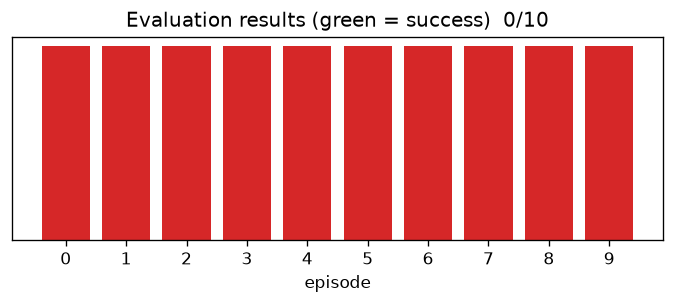

In [8]:
# 회차별 결과 시각화
colors = ["tab:green" if s else "tab:red" for s in res_df["success"]]
plt.figure(figsize=(7, 2.2))
plt.bar(res_df["episode"].astype(str), [1]*len(res_df), color=colors)
plt.yticks([]); plt.xlabel("episode")
plt.title(f"Evaluation results (green = success)  {n_success}/{len(res_df)}")
plt.show()

### 2-3. 평가 영상
평가 데이터셋은 [LeRobot Dataset Visualizer](https://huggingface.co/spaces/lerobot/visualize_dataset)에서 확인할 수 있다. 전체 10회가 실패했으므로 성공 GIF는 없으며, 에피소드 7을 대표 실패 장면으로 제시한다. 두 카메라 모두 대상 물체와 작업면이 충분히 보이지 않아 시각 정보가 제한적이었다.

![대표 실패 장면 — episode 7](images/failure.gif)

## 3. 고찰

**3-1. 실패 원인 분석**

10회 평가에서 모두 실패했으며, 실패 양상은 크게 두 가지로 나뉘었다. 에피소드 0, 5, 6, 9에서는 본드나 박스의 위치를 제대로 파악하지 못했고, 나머지 회차에서는 위치를 인식한 것으로 보였지만 그리퍼가 잡는 동작을 수행하지 않았다. 이는 정책이 시각 정보에서 물체 위치를 안정적으로 추정하지 못할 뿐 아니라, 접근 이후 그리퍼를 닫는 행동 순서도 충분히 학습하지 못했음을 보여 준다. 실행 중 `shoulder_lift` 목표가 안전 범위로 제한되는 경고도 반복되었지만, 이 경고가 실패의 직접 원인인지는 현재 기록만으로 단정할 수 없다.

**3-2. 데이터와 성능의 관계**

학습 데이터에서 물체 위치와 카메라 구도가 제한적이었다면, 평가 시 조금만 위치가 달라져도 정책이 대상을 찾지 못할 수 있다. 또한 시연마다 그리퍼를 닫는 시점이나 접근 경로가 일정하지 않았다면, 정책이 위치 인식 이후의 잡기 동작을 명확하게 학습하기 어렵다. 실제 평가 영상에서도 두 카메라에 대상 물체와 작업면이 충분히 보이지 않아 학습 때와 다른 시각 입력이 발생했을 가능성이 있다. 따라서 이번 0% 성공률은 학습 횟수만의 문제가 아니라 시연의 다양성·일관성과 평가 카메라 구도의 영향을 함께 받은 결과로 판단된다.

**3-3. 개선 아이디어**

먼저 overhead 카메라에는 전체 작업면과 두 물체가 보이도록 하고, wrist 카메라에는 그리퍼와 잡을 대상이 함께 들어오도록 위치를 고정해야 한다. 이후 물체의 시작 위치와 방향, 조명을 조금씩 바꾼 시연을 추가하되, 접근·정렬·그리퍼 닫기·들어 올리기 순서를 매번 일관되게 수행한다. 특히 위치는 찾았지만 잡지 않은 실패가 많았으므로 그리퍼를 닫는 구간이 분명한 성공 시연을 보강할 필요가 있다. 보강 데이터로 정책을 다시 학습한 뒤 동일한 조건에서 10회 평가하여 성공률과 실패 유형이 개선되는지 비교하겠다.

## 제출 전 체크리스트
아래 셀을 실행해 모든 항목이 통과하는지 확인한 뒤 커밋한다.

In [9]:
def repo_ok(rid, rtype):
    try:
        api.list_repo_files(rid, repo_type=rtype); return True
    except Exception:
        return False

def file_ok(rid, fname, rtype):
    try:
        hf_hub_download(rid, fname, repo_type=rtype); return True
    except Exception:
        return False

check_items = {
    "LeRobot 0.6.x 환경": bool(LEROBOT_VERSION) and LEROBOT_VERSION.startswith("0.6."),
    "학습 데이터셋 접근 가능 (public)": repo_ok(TRAIN_DATASET, "dataset"),
    "정책 모델 업로드됨 (config.json)": file_ok(POLICY_REPO, "config.json", "model"),
    "정책 가중치 업로드됨 (model.safetensors)": file_ok(POLICY_REPO, "model.safetensors", "model"),
    "평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)": EVAL_DATASET.split("/", 1)[-1].startswith("rollout_"),
    "평가 데이터셋 에피소드 10개": bool(info) and info.get("total_episodes") == 10,
    "회차별 결과 10개 입력": len(results) == 10,
    "실패 회차에 원인 기재": all(r["note"].strip() for r in results if not r["success"]),
}
for k, v in check_items.items():
    print(("[통과] " if v else "[미흡] ") + k)
print("\n모두 통과" if all(check_items.values()) else "\n미흡 항목을 보완한 뒤 커밋할 것")

[통과] LeRobot 0.6.x 환경
[통과] 학습 데이터셋 접근 가능 (public)
[통과] 정책 모델 업로드됨 (config.json)
[통과] 정책 가중치 업로드됨 (model.safetensors)
[통과] 평가 데이터셋 이름 rollout_로 시작 (lerobot-rollout 사용)
[통과] 평가 데이터셋 에피소드 10개
[통과] 회차별 결과 10개 입력
[통과] 실패 회차에 원인 기재

모두 통과
